# Лабораторная работа 3


In [1]:
%matplotlib inline

import bisect
import math
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    CountVectorizer,
    TfidfVectorizer,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.naive_bayes import MultinomialNB
from sklearn.utils.class_weight import compute_sample_weight

train_df = pd.read_csv("artifacts/train_clean.csv")
test_df = pd.read_csv("artifacts/test_clean.csv")

BUG_RE = re.compile(r"\b(?:bug|error|fail|crash|broken|exception|wrong|incorrect)\b")
FEAT_RE = re.compile(r"\b(?:feature|enhancement|request|support|improve|proposal)\b")
TOKEN_RE = re.compile(r"[a-z][a-z0-9_]+")
STOP_WORDS = set(ENGLISH_STOP_WORDS)
RANDOM_STATE = 42

def assign_label(title) -> str:
    text = "" if pd.isna(title) else str(title).lower()
    is_bug = BUG_RE.search(text) is not None
    is_feature = FEAT_RE.search(text) is not None
    if is_bug and is_feature:
        return "both"
    if is_bug:
        return "bug"
    if is_feature:
        return "feature"
    return "none"

def tokenize(text, drop_label_words=False) -> list[str]:
    if not isinstance(text, str):
        text = ""
    text = text.lower().replace("</s>", " ").replace("<s>", " ")
    if drop_label_words:
        text = BUG_RE.sub(" ", text)
        text = FEAT_RE.sub(" ", text)
    return [token for token in TOKEN_RE.findall(text) if token not in STOP_WORDS]

def analyze_for_classification(text) -> list[str]:
    return tokenize(text, drop_label_words=True)


Matplotlib is building the font cache; this may take a moment.


## Разметка классов

Метка берётся только из заголовка, как в лабораторной 2.

- `bug`: `bug`, `error`, `fail`, `crash`, `broken`, `exception`, `wrong`, `incorrect`
- `feature`: `feature`, `enhancement`, `request`, `support`, `improve`, `proposal`

В классификацию попадает документ, у которого сработал ровно один шаблон. Совпадения с обоими шаблонами (`both`) и заголовки без этих слов (`none`) остаются в корпусе для поиска и LDA, но не получают обучающую метку.

Слова из этих списков вырезаются из `body_clean` перед BoW и TF-IDF. Иначе классификатор мог бы повторить правило разметки, увидев то же слово в теле. Заголовок в признаки не входит.


In [2]:
train_df["label"] = train_df["issue_title"].map(assign_label)
test_df["label"] = test_df["issue_title"].map(assign_label)

def labeled_share(df):
    counts = df["label"].value_counts()
    labeled = df["label"].isin(["bug", "feature"])
    class_share = df.loc[labeled, "label"].value_counts(normalize=True)
    return counts, int(labeled.sum()), class_share

for name, df in [("train", train_df), ("test", test_df)]:
    counts, n_labeled, class_share = labeled_share(df)
    print(f"\n{name}: {len(df)} документов, в классификации {n_labeled}")
    print(counts.to_string())
    print(class_share.rename("доля среди размеченных").round(3).to_string())

train_labeled = train_df[train_df["label"].isin(["bug", "feature"])].reset_index(drop=True)
test_labeled = test_df[test_df["label"].isin(["bug", "feature"])].reset_index(drop=True)
y_train = train_labeled["label"].to_numpy()
y_test = test_labeled["label"].to_numpy()



train: 160000 документов, в классификации 21594
label
none       138192
bug         13227
feature      8367
both          214
label
bug        0.613
feature    0.387

test: 40000 документов, в классификации 5409
label
none       34541
bug         3266
feature     2143
both          50
label
bug        0.604
feature    0.396


## 1. Bag of Words и TF-IDF

Оба векторизатора используют один анализатор: из текста убираются `<s>` и `</s>`, остаются токены `[a-z][a-z0-9_]+`, отбрасываются английские стоп-слова и лексикон меток. `min_df=5` убирает редкий шум, `max_df=0.9` убирает слова, которые стоят почти в каждом документе.


In [3]:
count_vectorizer = CountVectorizer(analyzer=analyze_for_classification, min_df=5, max_df=0.9)
tfidf_vectorizer = TfidfVectorizer(analyzer=analyze_for_classification, min_df=5, max_df=0.9)

X_train_bow = count_vectorizer.fit_transform(train_labeled["body_clean"])
X_test_bow = count_vectorizer.transform(test_labeled["body_clean"])
X_train_tfidf = tfidf_vectorizer.fit_transform(train_labeled["body_clean"])
X_test_tfidf = tfidf_vectorizer.transform(test_labeled["body_clean"])

bow_names = count_vectorizer.get_feature_names_out()
tfidf_names = tfidf_vectorizer.get_feature_names_out()
print(f"BoW train {X_train_bow.shape}, test {X_test_bow.shape}")
print(f"TF-IDF train {X_train_tfidf.shape}, test {X_test_tfidf.shape}")
print("Число признаков совпадает:", X_train_bow.shape[1] == X_train_tfidf.shape[1])
print("Словари совпадают:", np.array_equal(bow_names, tfidf_names))
print("Пример признаков:", ", ".join(bow_names[:12]))

sample_text = train_labeled["body_clean"].iloc[0]
print("Токены первого размеченного документа:", analyze_for_classification(sample_text)[:25])


BoW train (21594, 9094), test (5409, 9094)
TF-IDF train (21594, 9094), test (5409, 9094)
Число признаков совпадает: True
Словари совпадают: True
Пример признаков: a0, a1, a2, a3, aa, aaa, aaaa, aac, ab, abandoned, abc, abc_iview
Токены первого размеченного документа: ['hi', 'wasn', 'sure', 'xmlextractor', 'example', 'supported', 'attributes', 'line', 'think', 'possibly', 'did', 'haven', 'luck', 'reading', 'attributes', 'xml', 'state', 'elementwriter', 'writeattributes', 'reader', 'false', 'thanks', 'alex']


## 2. Классификаторы

Оба алгоритма обучаются на TF-IDF train.

На размеченной выборке bug встречается примерно в 1.6 раза чаще feature. Поэтому для логистической регрессии включён `class_weight="balanced"`. У наивного байесовского классификатора применяется аналогичный по функционалу параметр: в `fit` передаётся `sample_weight`, вес документа обратно пропорционален частоте его класса, `n / (2 * n_class)`.


In [4]:
sample_weight = compute_sample_weight(class_weight="balanced", y=y_train)
for label in ["bug", "feature"]:
    print(f"sample_weight[{label}] = {sample_weight[y_train == label][0]:.4f}")

nb = MultinomialNB()
nb.fit(X_train_tfidf, y_train, sample_weight=sample_weight)

logreg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    solver="liblinear",
    random_state=RANDOM_STATE,
)
logreg.fit(X_train_tfidf, y_train)

def score_predictions(y_true, y_pred) -> dict:
    return {
        "macro_precision": precision_score(y_true, y_pred, average="macro", labels=["bug", "feature"]),
        "macro_recall": recall_score(y_true, y_pred, average="macro", labels=["bug", "feature"]),
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=["bug", "feature"]),
        "accuracy": accuracy_score(y_true, y_pred),
    }

nb_pred = nb.predict(X_test_tfidf)
logreg_pred = logreg.predict(X_test_tfidf)
metrics = pd.DataFrame(
    [
        score_predictions(y_test, nb_pred),
        score_predictions(y_test, logreg_pred),
    ],
    index=["MultinomialNB", "LogisticRegression"],
)
majority_accuracy = float((y_test == "bug").mean())
print(f"Baseline «всегда bug», accuracy = {majority_accuracy:.4f}")
display(metrics.round(4))


sample_weight[bug] = 0.8163
sample_weight[feature] = 1.2904
Baseline «всегда bug», accuracy = 0.6038


,macro_precision,macro_recall,macro_f1,accuracy
MultinomialNB,0.7795,0.7900,0.7816,0.7863
LogisticRegression,0.8005,0.8063,0.8028,0.8094


## 3. Почему accuracy не главная метрика

Accuracy - это доля документов. В размеченном test класс bug составляет около 60%, поэтому константный ответ «всегда bug» уже получает accuracy около 0.60.

Macro Precision, Macro Recall и Macro F1 считают bug и feature с одинаковым весом


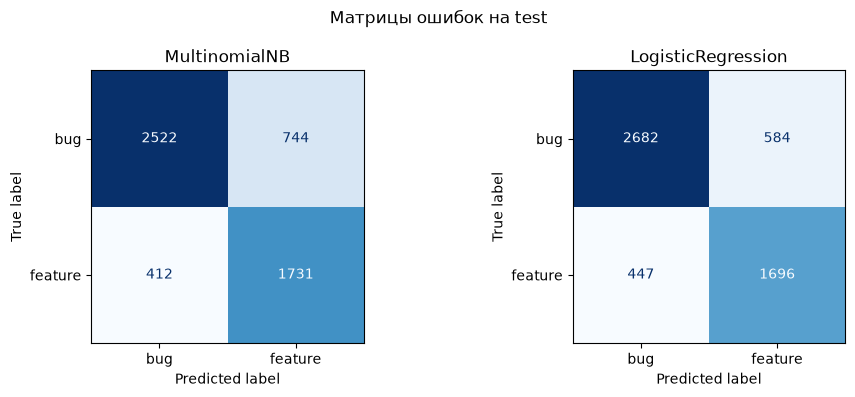

LogisticRegression, строки — истинный класс, столбцы — предсказание
[[2682  584]
 [ 447 1696]]


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, pred in zip(axes, ["MultinomialNB", "LogisticRegression"], [nb_pred, logreg_pred]):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred,
        labels=["bug", "feature"],
        ax=ax,
        colorbar=False,
        cmap="Blues",
    )
    ax.set_title(name)
fig.suptitle("Матрицы ошибок на test")
fig.tight_layout()
display(fig)
plt.close(fig)

print("LogisticRegression, строки — истинный класс, столбцы — предсказание")
print(confusion_matrix(y_test, logreg_pred, labels=["bug", "feature"]))


In [6]:
TITLE_PARTS = [
    "the add 1/0 is incorrect",
    "release_notes link in readme broken",
    "logrotate does not support ro root anymore",
    "request url 404 not found",
    "bad alloc crash with circuit involved",
]

confidence = logreg.predict_proba(X_test_tfidf).max(axis=1)
error_mask = logreg_pred != y_test
error_frame = test_labeled.loc[error_mask].copy()
error_frame["prediction"] = logreg_pred[error_mask]
error_frame["confidence"] = confidence[error_mask]

picked_rows = []
for part in TITLE_PARTS:
    hit = error_frame[error_frame["issue_title"].str.contains(part, regex=False)]
    if hit.empty:
        raise RuntimeError(f"Пример не найден среди ошибок: {part}")
    picked_rows.append(hit.iloc[0])

for number, row in enumerate(picked_rows, start=1):
    body = " ".join(str(row["body"]).split())
    print(f"\nПример {number}")
    print("Заголовок:", row["issue_title"])
    print("Истинная метка:", row["label"])
    print("Предсказание:", row["prediction"], f"(уверенность {row['confidence']:.3f})")
    print("Слов в body:", len(str(row["body"]).split()))
    print("Фрагмент body:", body[:400])



Пример 1
Заголовок: the add 1/0 is incorrect
Истинная метка: bug
Предсказание: feature (уверенность 0.969)
Слов в body: 27
Фрагмент body: currently it adds to the end of the path, which is dumb. it should add to one above the end making it a true change/receive useful tool.

Пример 2
Заголовок: release_notes link in readme broken
Истинная метка: bug
Предсказание: feature (уверенность 0.978)
Слов в body: 30
Фрагмент body: release notes https://github.com/fable-compiler/fable/blob/master/release_notes.md seem like the release notes are split up into many. if you let me know how you like to have, i will create a pr for that

Пример 3
Заголовок: logrotate does not support ro root anymore. the state file needs to move from /var/lib/logrotate.status to /var/lib/logrotate/status and rwtab entry should be changed to dirs /var/lib/logrotate
Истинная метка: feature
Предсказание: bug (уверенность 0.952)
Слов в body: 21
Фрагмент body: https://bugzilla.redhat.com/show_bug.cgi?id=1272236 has this i

## 4. Инвертированный индекс

Индекс строится по всему корпусу train и test, 200 000 документов, по `body_clean` без вырезания слов-меток. Номер - позиция в объединенном датасете: train `0…159999`, test `160000…199999`.


In [7]:
corpus_titles = pd.concat(
    [train_df["issue_title"].fillna(""), test_df["issue_title"].fillna("")],
    ignore_index=True,
)
corpus_bodies = pd.concat(
    [train_df["body"].fillna(""), test_df["body"].fillna("")],
    ignore_index=True,
)
corpus_body_clean = pd.concat(
    [train_df["body_clean"].fillna(""), test_df["body_clean"].fillna("")],
    ignore_index=True,
)
tokenized_docs = [tokenize(text) for text in corpus_body_clean]

inverted_index = defaultdict(list)
term_freqs = defaultdict(list)
document_length = []
for doc_id, tokens in enumerate(tokenized_docs):
    document_length.append(len(tokens))
    for term, freq in Counter(tokens).items():
        inverted_index[term].append(doc_id)
        term_freqs[term].append(freq)
inverted_index = dict(inverted_index)
term_freqs = dict(term_freqs)

example_term = "exception"
print(f"Документов в корпусе: {len(document_length)}")
print(f"Терминов в индексе: {len(inverted_index)}")
print(f"Постинг «{example_term}»: {len(inverted_index[example_term])} документов")
print("Первые doc_id:", inverted_index[example_term][:8])
print("Частоты этих документов:", term_freqs[example_term][:8])
print("Списки doc_id отсортированы:", inverted_index[example_term] == sorted(inverted_index[example_term]))
print("Заголовки первых документов:")
for doc_id in inverted_index[example_term][:5]:
    print(f"  {doc_id}: {corpus_titles.iloc[doc_id]}")


Документов в корпусе: 200000
Терминов в индексе: 346347
Постинг «exception»: 3400 документов
Первые doc_id: [77, 143, 270, 317, 369, 393, 512, 591]
Частоты этих документов: [1, 3, 1, 1, 1, 1, 1, 1]
Списки doc_id отсортированы: True
Заголовки первых документов:
  77: terminal.eraseline gives overflowerror on windows
  143: typeerror: build_attrs takes from 1 to 2 positional arguments but 3 were given
  270: failure: build failed with an exception.
  317: cast text column to integer for the postgresql
  369: game crashes in-game while hosting and someone joins


## 5. Поиск Okapi BM25

$$
\mathrm{IDF}(q)=\ln\left(\frac{N-\mathrm{df}+0.5}{\mathrm{df}+0.5}+1\right)
$$

$$
\mathrm{score}(d,Q)=\sum_{q \in Q}\mathrm{IDF}(q)\cdot\frac{\mathrm{tf}(q,d)\,(k_1+1)}{\mathrm{tf}(q,d)+k_1\left(1-b+b\frac{|d|}{\mathrm{avgdl}}\right)}
$$

Параметры: $k_1=1.5$, $b=0.75$. Кандидаты берутся из инвертированного индекса.


In [8]:
def bm25_search(query, k=5, k1=1.5, b=0.75):
    terms = tokenize(query)
    n_docs = len(document_length)
    avgdl = sum(document_length) / n_docs
    unique_terms = list(dict.fromkeys(terms))
    posting_sets = [set(inverted_index[term]) for term in unique_terms if term in inverted_index]
    intersection = set.intersection(*posting_sets) if posting_sets else set()
    candidate_ids = set.union(*posting_sets) if posting_sets else set()

    scored = []
    for doc_id in candidate_ids:
        dl = document_length[doc_id]
        score = 0.0
        for term in terms:
            postings = inverted_index.get(term)
            if not postings:
                continue
            pos = bisect.bisect_left(postings, doc_id)
            if pos >= len(postings) or postings[pos] != doc_id:
                continue
            tf = term_freqs[term][pos]
            df = len(postings)
            idf = math.log((n_docs - df + 0.5) / (df + 0.5) + 1.0)
            denominator = tf + k1 * (1.0 - b + b * dl / avgdl)
            score += idf * tf * (k1 + 1.0) / denominator
        scored.append((score, doc_id))
    scored.sort(key=lambda item: (-item[0], item[1]))
    return terms, intersection, scored[:k]

queries = [
    "crash null pointer exception",
    "feature proposal configuration option",
    "how to install and configure",
]
for query in queries:
    terms, intersection, hits = bm25_search(query)
    print(f"\nЗапрос: {query}")
    print("Термы после токенизации:", terms)
    print("Документов в полном пересечении термов:", len(intersection))
    rows = []
    for rank, (score, doc_id) in enumerate(hits, start=1):
        snippet = " ".join(str(corpus_bodies.iloc[doc_id]).split())
        rows.append(
            {
                "rank": rank,
                "doc_id": doc_id,
                "score": round(score, 4),
                "issue_title": corpus_titles.iloc[doc_id],
                "snippet": snippet[:180],
            }
        )
    display(pd.DataFrame(rows))



Запрос: crash null pointer exception
Термы после токенизации: ['crash', 'null', 'pointer', 'exception']
Документов в полном пересечении термов: 1


,rank,doc_id,score,issue_title,snippet
0,1,103231,23.5209,exceptions from renameshortname,throws null pointer exception. i disabled it f...
1,2,157515,21.8566,isolated workspaces backwards compatibility issue,loading a data directory with isolated workspa...
2,3,157698,21.8566,testsslauth fails with null pointer exception,this is with respect to the okhttp change and ...
3,4,135960,21.1098,clear filters causes unhandled exception,when in state produced by 75 hitting clear fil...
4,5,133124,21.0161,cheetah digital sdk 1.2: app crashes when ems_...,"hi, i am using test push notifications website..."



Запрос: feature proposal configuration option
Термы после токенизации: ['feature', 'proposal', 'configuration', 'option']
Документов в полном пересечении термов: 2


,rank,doc_id,score,issue_title,snippet
0,1,9252,20.4804,add autocomplete= off to all configuration inputs,this is a feature proposal description add aut...
1,2,51083,16.4693,you should be able to turn off resource versio...,feature request what challenge are you facing?...
2,3,161499,16.0784,feature request: use cosmiconfig for configura...,<!-- please answer the following questions. is...
3,4,168590,14.6617,support identityvalidationexpression on author...,feature proposal description support identityv...
4,5,25706,14.3928,remove old gallery view,feature proposal the old gallery view can be r...



Запрос: how to install and configure
Термы после токенизации: ['install', 'configure']
Документов в полном пересечении термов: 206


,rank,doc_id,score,issue_title,snippet
0,1,3674,12.9421,create a build script,create a shell script to automatically install...
1,2,194640,12.8149,find and install drivers for apple keyboard & ...,less important work from 9 - find drivers extr...
2,3,55997,12.3694,disable installation/configuration for gdeploy...,as crud is not available for the gluster entit...
3,4,97788,12.1668,rpm spec file for fedora build,just created a package for fedora @ https://co...
4,5,140344,12.1581,install mongo/psql database,install and configure either a mongodb or post...


## 6. LDA и coherence $C_V$

Словарь gensim строится по всем 200 000 документам: `no_below=10`, `no_above=0.5`, не больше 10 000 слов. Подбор числа тем и финальная модель считаются на случайной подвыборке 20 000 документов. Coherence $C_V$ по полному корпусу слишком тяжелый, поэтому на графике расчеты для то1 же фиксированно1 подвыборки.

Сетка K: 2, 4, 6, 8, 10, 12, 15, 20. Модель: `passes=10`, `iterations=50`.


Слов в словаре LDA: 10000


Документов в подвыборке coherence: 20000


K=2: coherence c_v=0.5048


K=4: coherence c_v=0.4513


K=6: coherence c_v=0.4788


K=8: coherence c_v=0.4747


K=10: coherence c_v=0.4960


K=12: coherence c_v=0.5017


K=15: coherence c_v=0.4816


K=20: coherence c_v=0.5079
Максимум при K=20 (0.5079)
Выбранное K=20 (0.5079)


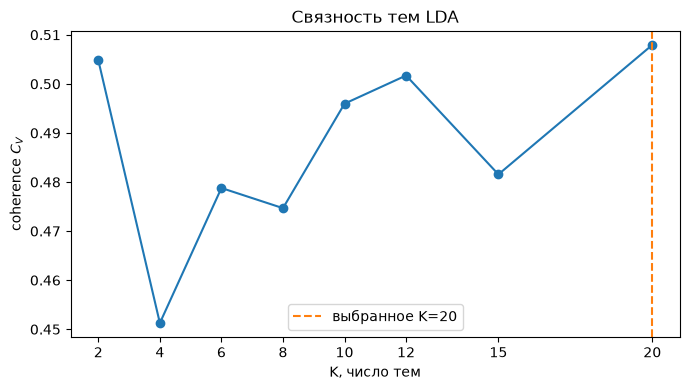


Топ-10 слов для K=20
Тема 0: js (0.115), module (0.062), node (0.036), src (0.032), url (0.025), node_modules (0.024), index (0.022), error (0.022), tutorial (0.022), object (0.021)
Тема 1: key (0.074), flow (0.052), uk (0.042), south (0.039), control (0.029), role (0.017), queue (0.014), blocks (0.012), logic (0.011), contact (0.011)
Тема 2: type (0.021), value (0.020), like (0.018), use (0.018), class (0.017), string (0.014), import (0.013), using (0.012), input (0.011), set (0.011)
Тема 3: nonlatin (0.613), la (0.017), url (0.016), en (0.014), que (0.013), el (0.012), se (0.008), le (0.008), na (0.007), kodi (0.007)
Тема 4: app (0.058), android (0.024), device (0.018), run (0.016), build (0.013), ios (0.012), react (0.012), task (0.011), native (0.010), running (0.010)
Тема 5: url (0.164), issue (0.026), user (0.013), comment (0.013), settings (0.011), card (0.011), project (0.011), details (0.009), add (0.009), token (0.009)
Тема 6: num (0.631), version (0.017), error (0.006), url

In [9]:
import logging

from gensim.corpora import Dictionary
from gensim.models import LdaModel
from gensim.models.coherencemodel import CoherenceModel

logging.getLogger("gensim").setLevel(logging.ERROR)

dictionary = Dictionary(tokenized_docs)
dictionary.filter_extremes(no_below=10, no_above=0.5, keep_n=10000)
print(f"Слов в словаре LDA: {len(dictionary)}")

sample_rng = np.random.default_rng(RANDOM_STATE)
sample_idx = np.sort(sample_rng.choice(len(tokenized_docs), size=20000, replace=False))
sample_tokens = [tokenized_docs[i] for i in sample_idx]
sample_corpus = [dictionary.doc2bow(tokens) for tokens in sample_tokens]
print(f"Документов в подвыборке coherence: {len(sample_tokens)}")

k_grid = [2, 4, 6, 8, 10, 12, 15, 20]
coherence_by_k = {}
lda_models = {}
for k in k_grid:
    lda = LdaModel(
        corpus=sample_corpus,
        id2word=dictionary,
        num_topics=k,
        random_state=RANDOM_STATE,
        passes=10,
        iterations=50,
        eval_every=None,
        chunksize=2000,
    )
    coherence = CoherenceModel(
        model=lda,
        texts=sample_tokens,
        dictionary=dictionary,
        coherence="c_v",
        processes=1,
    ).get_coherence()
    coherence_by_k[k] = float(coherence)
    lda_models[k] = lda
    print(f"K={k}: coherence c_v={coherence:.4f}")

k_star = max(k_grid, key=coherence_by_k.get)
chosen_k = k_star
chosen_pos = k_grid.index(k_star)
while chosen_pos > 0 and coherence_by_k[k_star] - coherence_by_k[k_grid[chosen_pos - 1]] <= 0.01:
    chosen_pos -= 1
    chosen_k = k_grid[chosen_pos]
print(f"Максимум при K={k_star} ({coherence_by_k[k_star]:.4f})")
print(f"Выбранное K={chosen_k} ({coherence_by_k[chosen_k]:.4f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_grid, [coherence_by_k[k] for k in k_grid], marker="o")
ax.axvline(chosen_k, color="C1", linestyle="--", label=f"выбранное K={chosen_k}")
ax.set_xlabel("K, число тем")
ax.set_ylabel("coherence $C_V$")
ax.set_title("Связность тем LDA")
ax.set_xticks(k_grid)
ax.legend()
fig.tight_layout()
display(fig)
plt.close(fig)

final_lda = lda_models[chosen_k]
print(f"\nТоп-10 слов для K={chosen_k}")
for topic_id, words in final_lda.show_topics(num_topics=chosen_k, num_words=10, formatted=False):
    formatted = ", ".join(f"{word} ({weight:.3f})" for word, weight in words)
    print(f"Тема {topic_id}: {formatted}")


## 7. Интерпретация тем

Максимум coherence на сетке - K=20, $C_V = 0.5079$. Соседняя точка K=15 даёт 0.4816, разрыв больше 0.01, поэтому правило оставляет K=20. Точка K=2 тоже высокая (0.5048), но на этой сетке она не соседняя с максимумом.

Токены `num`, `url`, `hex`, `nonlatin` - это следы очистки лабораторной 1: `[num]`, `[url]`, `[hex]`, `[nonlatin]`. Скобки токенизатор снимает, и такие слова попадают в темы как обычные.

0. **Модули Node.js.** `js`, `module`, `node`, `node_modules`, `src`, `tutorial`, `object`, `error`. Сборка JavaScript-пакетов и ошибки в модулях.
1. **Потоки управления и роли.** `key`, `flow`, `control`, `role`, `queue`, `blocks`, `logic`. Слова `uk` и `south` в этот ряд не складываются: тема рыхлая, часть веса сидит на случайных географических упоминаниях.
2. **Типы и классы в коде.** `type`, `value`, `class`, `string`, `import`, `input`, `set`. Обсуждение типов данных и импортов.
3. **Неанглийский текст.** `nonlatin` с весом 0.613 и служебные слова других языков: `la`, `que`, `el`, `se`, `le`. Тема собирает issue на других языках: нелатинские алфавиты и романские служебные слова.
4. **Мобильные приложения.** `app`, `android`, `ios`, `device`, `react`, `native`, `build`, `run`. Сборка и запуск мобильных клиентов.
5. **Ссылки и карточки issue.** `url`, `issue`, `comment`, `user`, `settings`, `card`, `token`, `project`. Переписка вокруг ссылок, настроек и карточек.
6. **Номера версий и коды ошибок.** `num` с весом 0.631, дальше `version`, `error`, `err`, `os`, `linux`, `pm`. Документы, насыщенные числами: версии, коды, время.
7. **Java и базы данных.** `java`, `id`, `data`, `model`, `database`, `com`, `org`. Идентификаторы, модели и хранилища в Java-проектах.
8. **Пути и стектрейсы Python.** `file`, `line`, `py`, `python`, `lib`, `path`, `local`, `home`, `usr`, `packages`. Файловые пути и строки из трассировок.
9. **Пользователи, страницы и формы.** `user`, `page`, `list`, `view`, `form`, `event`, `message`, `add`, `create`. Интерфейсные сущности: создать пользователя, страницу, форму.
10. **Docker и служебные идентификаторы.** `docker`, `container`, `tag`, `github`, `xml`, `vendor`, `response`, `src`, `hex`. Сборка контейнеров рядом с хешами и тегами.
11. **API, клиент и сессия.** `server`, `api`, `client`, `request`, `login`, `session`, `access`, `profile`, `application`. Сетевой доступ и авторизация.
12. **CI и обновление зависимостей.** `ci`, `branch`, `repository`, `greenkeeper`, `item`, `add`, `set`. Ветки репозитория и бот Greenkeeper, который обновляет зависимости.
13. **Общие формулы вежливости.** `hi`, `thanks`, `just`, `like`, `use`, `using`, `work`, `project`, `package`. Узкого предмета нет: это зачины писем вроде «hi, I would like… thanks».
14. **Шаблон баг-репорта.** `expected`, `behavior`, `actual`, `steps`, `reproduce`, `bug`, `version`, `description`. Стандартная форма: шаги, ожидаемое и фактическое поведение.
15. **Фрагменты кода.** `function`, `return`, `var`, `let`, `true`, `false`, `end`, `table`. Вставленный код с функциями и булевыми значениями.
16. **Тесты и падения прогона.** `test`, `tests`, `error`, `failed`, `run`, `running`, `log`, `message`, `code`. Неуспешные тесты и логи.
17. **Браузер и клики по интерфейсу.** `page`, `link`, `browser`, `chrome`, `screen`, `window`, `click`, `button`, `video`. Поведение страницы в браузере.
18. **Изображения и вёрстка.** `image`, `images`, `size`, `css`, `left`, `right`, `player`. Размеры картинок, CSS и плеер.
19. **Редактор и HTML-оформление.** `text`, `title`, `color`, `html`, `content`, `editor`, `theme`, `atom`, `controller`. Темы оформления и редактор Atom.
